<a href="https://colab.research.google.com/github/fernandaelenn/fernandaelenn/blob/main/script_media_climaticas_inmet_NAVIO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Resumos climáticos INMET por período e por dia

Lê o CSV horário bruto do INMET, filtra o intervalo de datas e gera:
- médias de temperatura e umidade por **período** (Manhã, Tarde, Noite);
- resumo **diário** (média dos três períodos) com **chuva acumulada** do dia;
- análise exploratória (extremos e gráficos).

Os CSVs são salvos com ponto decimal (`35.5`).

In [1]:
import re
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

## 1. Configuração

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [29]:
ARQUIVO_ENTRADA = Path("")   # CSV bruto do INMET
PASTA_SAIDA = Path("saida")

DATA_INICIO = "2026-03-21"
DATA_FIM = "2026-03-22"

# Horas do arquivo estão em UTC. Use -4 para converter para horário local
# (MT/MS). Com 0 as horas são usadas exatamente como estão no arquivo.
DESLOCAMENTO_HORAS = 0

COL_DATA = "Data"
COL_HORA = "Hora (UTC)"
COL_CHUVA = "Chuva (mm)"

# Variáveis médias (temperatura e umidade) -> nome na saída
VARIAVEIS = {
    "Temp. Ins. (C)": "Temp. Ins. Média (°C)",
    "Temp. Max. (C)": "Temp. Max. Média (°C)",
    "Temp. Min. (C)": "Temp. Min. Média (°C)",
    "Umi. Ins. (%)": "Umi. Ins. Média (%)",
    "Umi. Max. (%)": "Umi. Max. Média (%)",
    "Umi. Min. (%)": "Umi. Min. Média (%)",
}
ORDEM_PERIODOS = ["Manhã", "Tarde", "Noite"]

PASTA_SAIDA.mkdir(exist_ok=True)

## 2. Funções auxiliares

In [30]:
def ler_csv(caminho):
    """Lê o CSV detectando separador (',' ou ';') e codificação."""
    for enc in ("utf-8-sig", "latin-1"):
        try:
            with open(caminho, encoding=enc) as f:
                cabecalho = f.readline()
            sep = ";" if cabecalho.count(";") > cabecalho.count(",") else ","
            return pd.read_csv(caminho, sep=sep, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError("Não foi possível ler o arquivo.")


def para_numero(serie):
    """Converte textos como '35,5' em 35.5; -9999 (sem dado) vira NaN."""
    s = serie.astype(str).str.strip().str.replace(",", ".", regex=False)
    return pd.to_numeric(s, errors="coerce").replace(-9999, float("nan"))


def extrair_hora(valor):
    """Aceita 600, '0600', '06:00' ou '0600 UTC' e devolve a hora (0-23)."""
    digitos = re.sub(r"\D", "", str(valor))
    if not digitos:
        return pd.NA
    return (int(digitos) // 100) % 24


def categorizar_periodo(hora):
    if pd.isna(hora):
        return pd.NA
    if 6 <= hora < 12:
        return "Manhã"
    if 12 <= hora < 18:
        return "Tarde"
    return "Noite"

## 3. Leitura e filtro de datas

In [31]:
df = ler_csv(ARQUIVO_ENTRADA)
df.columns = df.columns.str.strip()

faltando = [c for c in [COL_DATA, COL_HORA, COL_CHUVA, *VARIAVEIS] if c not in df.columns]
if faltando:
    raise KeyError(f"Colunas não encontradas no CSV: {faltando}")

df[COL_DATA] = pd.to_datetime(df[COL_DATA], format="mixed", dayfirst=True).dt.normalize()
df = df.loc[df[COL_DATA].between(DATA_INICIO, DATA_FIM)].copy()

print(f"Registros no intervalo: {len(df)} | Dias: {df[COL_DATA].nunique()}")
display(df.head())

Registros no intervalo: 48 | Dias: 2


,Data,Hora (UTC),Temp. Ins. (C),Temp. Max. (C),Temp. Min. (C),Umi. Ins. (%),Umi. Max. (%),Umi. Min. (%),Pto Orvalho Ins. (C),Pto Orvalho Max. (C),Pto Orvalho Min. (C),Pressao Ins. (hPa),Pressao Max. (hPa),Pressao Min. (hPa),Vel. Vento (m/s),Dir. Vento (m/s),Raj. Vento (m/s),Radiacao (KJ/m²),Chuva (mm)
0,2026-03-21,0,"27,5","27,8","27,5","76,0","76,0","74,0","22,9","22,9","22,8","992,5","992,5","991,6",NaN,"109,0",NaN,NaN,"0,4"
1,2026-03-21,100,"27,2","27,5","27,2","77,0","77,0","76,0","22,9","22,9","22,8","993,2","993,2","992,5",NaN,"90,0",NaN,NaN,"0,0"
2,2026-03-21,200,"27,1","27,3","27,1","79,0","79,0","77,0","23,2","23,2","23,0","993,6","993,7","993,2",NaN,"82,0",NaN,NaN,"0,0"
3,2026-03-21,300,"26,6","27,1","26,5","81,0","81,0","79,0","23,1","23,1","22,9","993,5","993,8","993,5",NaN,"86,0",NaN,NaN,"0,0"
4,2026-03-21,400,"26,5","26,6","26,4","83,0","83,0","81,0","23,3","23,3","23,1","993,2","993,5","993,1",NaN,"83,0",NaN,NaN,"0,0"


## 4. Conversão para números e períodos

In [32]:
for coluna in [*VARIAVEIS, COL_CHUVA]:
    df[coluna] = para_numero(df[coluna])

hora = df[COL_HORA].apply(extrair_hora)
df["Período"] = ((hora + DESLOCAMENTO_HORAS) % 24).apply(categorizar_periodo)

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 48 entries, 0 to 47
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Data                  48 non-null     datetime64[ns]
 1   Hora (UTC)            48 non-null     int64         
 2   Temp. Ins. (C)        48 non-null     float64       
 3   Temp. Max. (C)        48 non-null     float64       
 4   Temp. Min. (C)        48 non-null     float64       
 5   Umi. Ins. (%)         48 non-null     float64       
 6   Umi. Max. (%)         48 non-null     float64       
 7   Umi. Min. (%)         48 non-null     float64       
 8   Pto Orvalho Ins. (C)  48 non-null     object        
 9   Pto Orvalho Max. (C)  48 non-null     object        
 10  Pto Orvalho Min. (C)  48 non-null     object        
 11  Pressao Ins. (hPa)    48 non-null     object        
 12  Pressao Max. (hPa)    48 non-null     object        
 13  Pressao Min. (hPa)    48 no

## 5. Médias por período

In [33]:
medias_periodo = (
    df.groupby([COL_DATA, "Período"])[list(VARIAVEIS)]
    .mean()
    .rename(columns=VARIAVEIS)
    .reset_index()
)
medias_periodo["Período"] = pd.Categorical(
    medias_periodo["Período"], categories=ORDEM_PERIODOS, ordered=True
)
medias_periodo = medias_periodo.sort_values([COL_DATA, "Período"]).reset_index(drop=True)

display(medias_periodo.round(2))

,Data,Período,Temp. Ins. Média (°C),Temp. Max. Média (°C),Temp. Min. Média (°C),Umi. Ins. Média (%),Umi. Max. Média (%),Umi. Min. Média (%)
0,2026-03-21,Manhã,25.87,26.03,25.63,83.83,83.83,83.67
1,2026-03-21,Tarde,30.33,31.08,29.12,70.17,74.67,70.00
2,2026-03-21,Noite,28.67,29.39,28.33,71.00,71.50,68.83
3,2026-03-22,Manhã,25.80,26.02,25.53,80.00,80.00,79.17
4,2026-03-22,Tarde,31.65,32.13,30.10,64.83,69.17,64.67
5,2026-03-22,Noite,29.14,30.18,28.57,67.92,69.42,65.08


## 6. Resumo diário
Média dos três períodos para cada variável + chuva acumulada do dia.

In [34]:
medias_diarias = (
    medias_periodo.groupby(COL_DATA, observed=True)[list(VARIAVEIS.values())]
    .mean()
)

# min_count=1: dia sem nenhum registro de chuva fica vazio, e não 0
medias_diarias["Chuva Acumulada (mm)"] = df.groupby(COL_DATA)[COL_CHUVA].sum(min_count=1)
medias_diarias = medias_diarias.reset_index()

display(medias_diarias.round(2))

,Data,Temp. Ins. Média (°C),Temp. Max. Média (°C),Temp. Min. Média (°C),Umi. Ins. Média (%),Umi. Max. Média (%),Umi. Min. Média (%),Chuva Acumulada (mm)
0,2026-03-21,28.29,28.84,27.69,75.00,76.67,74.17,0.4
1,2026-03-22,28.86,29.44,28.07,70.92,72.86,69.64,3.0


## 7. Salvar CSVs (ponto decimal)

In [35]:
def salvar(tabela, nome):
    saida = tabela.copy()
    saida[COL_DATA] = saida[COL_DATA].dt.strftime("%d/%m/%Y")
    caminho = PASTA_SAIDA / nome
    saida.to_csv(caminho, index=False, sep=";", decimal=".",
                 float_format="%.2f", encoding="utf-8-sig")
    return caminho


print(salvar(medias_periodo, "medias_por_periodo.csv"))
print(salvar(medias_diarias, "resumo_diario.csv"))

# Conferir o conteúdo real do arquivo
print((PASTA_SAIDA / "resumo_diario.csv").read_text(encoding="utf-8-sig")[:600])

saida/medias_por_periodo.csv
saida/resumo_diario.csv
Data;Temp. Ins. Média (°C);Temp. Max. Média (°C);Temp. Min. Média (°C);Umi. Ins. Média (%);Umi. Max. Média (%);Umi. Min. Média (%);Chuva Acumulada (mm)
21/03/2026;28.29;28.84;27.69;75.00;76.67;74.17;0.40
22/03/2026;28.86;29.44;28.07;70.92;72.86;69.64;3.00



## 8. Análise exploratória

In [36]:
from pathlib import Path
from google.colab import drive, files

# Montar o Google Drive
drive.mount("/content/drive")

# Configurações de exportação
TIPO_RESUMO = "diario"  # "diario" ou "periodo"

PASTA_SAIDA = Path(
    ""
)

BAIXAR_ARQUIVO = False  # True para baixar também no computador

# Selecionar tabela e nome do arquivo
if TIPO_RESUMO == "diario":
    tabela_exportar = medias_diarias
    nome_arquivo = "medias_climaticas_diarias.csv"

elif TIPO_RESUMO == "periodo":
    tabela_exportar = medias_por_periodo
    nome_arquivo = "medias_climaticas_por_periodo.csv"

else:
    raise ValueError('TIPO_RESUMO deve ser "diario" ou "periodo".')

# Criar pasta caso não exista
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

# Caminho completo do CSV
caminho_csv = PASTA_SAIDA / nome_arquivo

# Exportar CSV
tabela_exportar.to_csv(
    caminho_csv,
    index=False,
    sep=";",
    decimal=".",
    float_format="%.2f",
    date_format="%d/%m/%Y",
    encoding="utf-8-sig"
)

print(f"CSV salvo com sucesso em:\n{caminho_csv}")

# Download opcional
if BAIXAR_ARQUIVO:
    files.download(str(caminho_csv))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CSV salvo com sucesso em:
medias_climaticas_diarias.csv


In [37]:
display(medias_diarias.drop(columns=COL_DATA).describe().round(2))

criterios = [
    ("Dia mais chuvoso", "Chuva Acumulada (mm)", "idxmax"),
    ("Dia mais quente", "Temp. Max. Média (°C)", "idxmax"),
    ("Dia menos quente", "Temp. Min. Média (°C)", "idxmin"),
    ("Dia mais úmido", "Umi. Max. Média (%)", "idxmax"),
    ("Dia menos úmido", "Umi. Min. Média (%)", "idxmin"),
]

linhas = []
for rotulo, coluna, funcao in criterios:
    serie = medias_diarias[coluna]
    if serie.notna().any():
        i = getattr(serie, funcao)()
        linhas.append({
            "Condição": rotulo,
            "Data": medias_diarias.loc[i, COL_DATA].strftime("%d/%m/%Y"),
            "Variável": coluna,
            "Valor": round(serie[i], 2),
        })

extremos = pd.DataFrame(linhas)
display(extremos)
extremos.to_csv(PASTA_SAIDA / "extremos.csv", index=False, sep=";", decimal=".", encoding="utf-8-sig")

,Temp. Ins. Média (°C),Temp. Max. Média (°C),Temp. Min. Média (°C),Umi. Ins. Média (%),Umi. Max. Média (%),Umi. Min. Média (%),Chuva Acumulada (mm)
count,2.00,2.00,2.00,2.00,2.00,2.00,2.00
mean,28.58,29.14,27.88,72.96,74.76,71.90,1.70
std,0.41,0.43,0.26,2.89,2.69,3.20,1.84
min,28.29,28.84,27.69,70.92,72.86,69.64,0.40
25%,28.43,28.99,27.79,71.94,73.81,70.77,1.05
50%,28.58,29.14,27.88,72.96,74.76,71.90,1.70
75%,28.72,29.29,27.97,73.98,75.72,73.03,2.35
max,28.86,29.44,28.07,75.00,76.67,74.17,3.00


,Condição,Data,Variável,Valor
0,Dia mais chuvoso,22/03/2026,Chuva Acumulada (mm),3.00
1,Dia mais quente,22/03/2026,Temp. Max. Média (°C),29.44
2,Dia menos quente,21/03/2026,Temp. Min. Média (°C),27.69
3,Dia mais úmido,21/03/2026,Umi. Max. Média (%),76.67
4,Dia menos úmido,22/03/2026,Umi. Min. Média (%),69.64


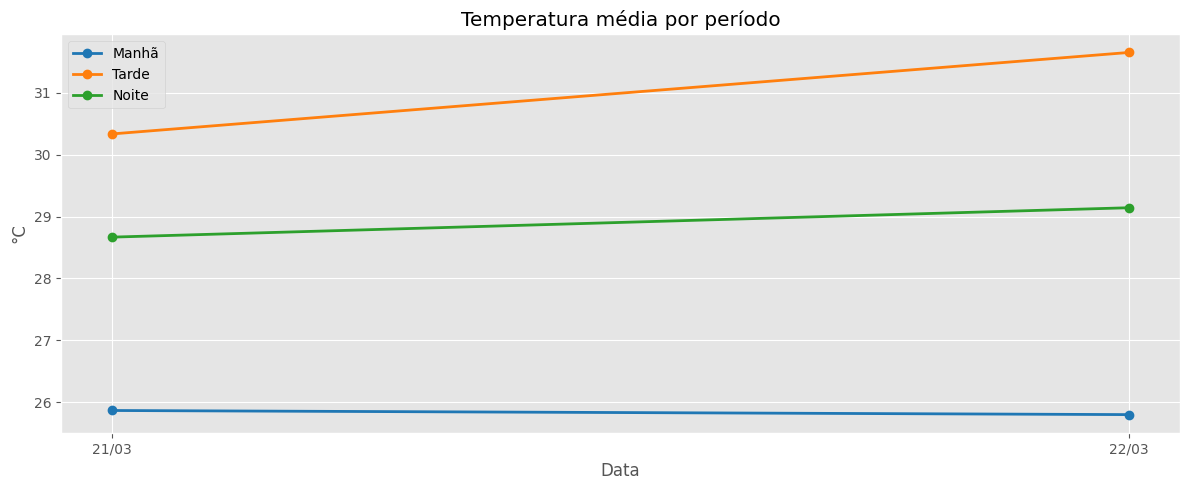

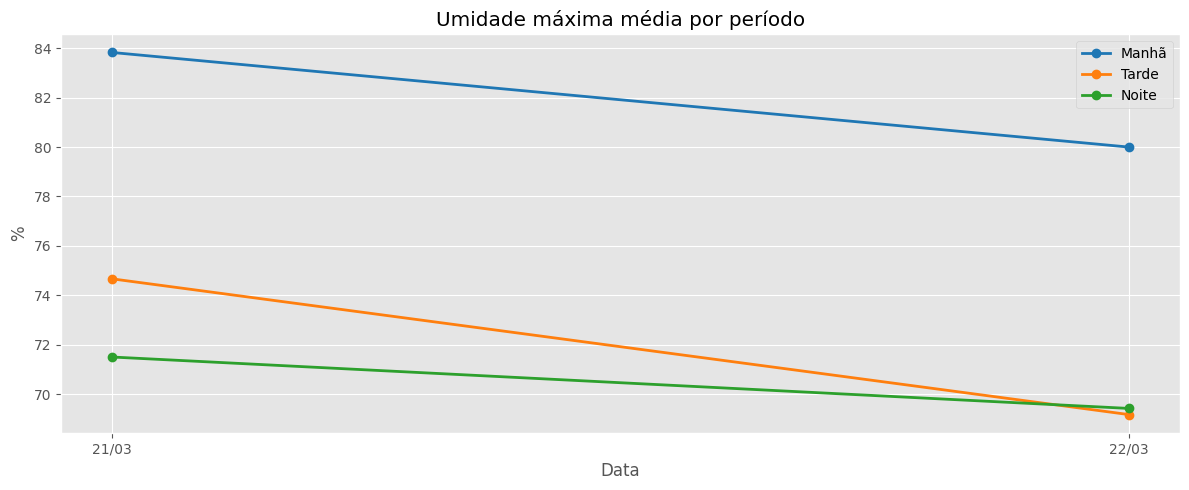

In [38]:
plt.style.use("ggplot")
CORES = {"Manhã": "#1f77b4", "Tarde": "#ff7f0e", "Noite": "#2ca02c"}


def grafico_periodos(coluna, titulo, eixo_y, arquivo):
    fig, ax = plt.subplots(figsize=(12, 5))
    for periodo in ORDEM_PERIODOS:
        d = medias_periodo[medias_periodo["Período"] == periodo]
        ax.plot(d[COL_DATA], d[coluna], marker="o", lw=2, label=periodo, color=CORES[periodo])
    ax.set(title=titulo, xlabel="Data", ylabel=eixo_y)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.legend()
    fig.tight_layout()
    fig.savefig(PASTA_SAIDA / arquivo, dpi=200)
    plt.show()


grafico_periodos("Temp. Ins. Média (°C)", "Temperatura média por período", "°C", "grafico_temperatura.png")
grafico_periodos("Umi. Max. Média (%)", "Umidade máxima média por período", "%", "grafico_umidade.png")

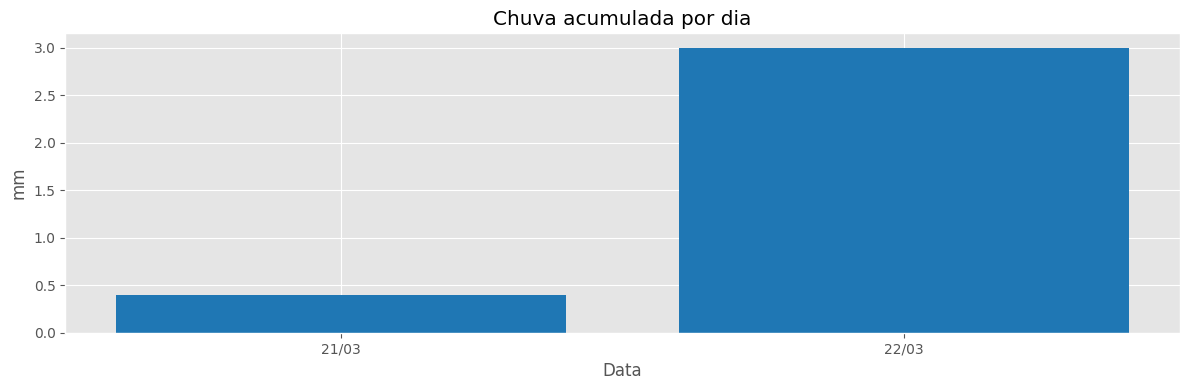

In [39]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(medias_diarias[COL_DATA], medias_diarias["Chuva Acumulada (mm)"], color="#1f77b4")
ax.set(title="Chuva acumulada por dia", xlabel="Data", ylabel="mm")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.xaxis.set_major_locator(mdates.DayLocator())
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "grafico_chuva.png", dpi=200)
plt.show()